<a href="https://colab.research.google.com/github/rey24ti/2TIE-Fransiskus-Rey-main/blob/main/propstat_tugas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from math import comb
from scipy.stats import binom, poisson, norm, expon, hypergeom

# Styling global
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.float_format", lambda v: f"{v:.6f}")

print("✅ Setup selesai. Library siap dipakai.")

✅ Setup selesai. Library siap dipakai.


────────────────────────────────────────────────────────────
STUDI KASUS 2.1 — Alokasi Server (Hipergeometrik)
────────────────────────────────────────────────────────────
 x  P(X=x) manual
 0       0.254545
 1       0.509091
 2       0.218182
 3       0.018182

P(X>=1) manual : 0.745455   (eksak 41/55 = 0.745455)
E[X] manual    : 1.000000
SciPy PMF      : [0.254545 0.509091 0.218182 0.018182]
SciPy mean     : 1.000000
MC P(X>=1)     : 0.746280 ± 0.001907 (95% CI)
MC E[X]        : 1.0009


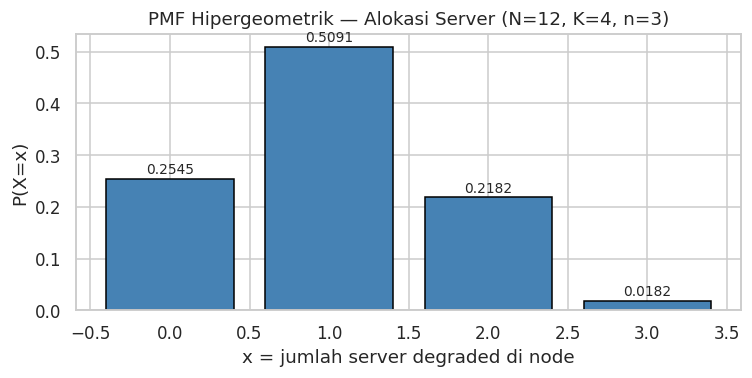

In [ ]:
print("─" * 60)
print("STUDI KASUS 2.1 — Alokasi Server (Hipergeometrik)")
print("─" * 60)

N, K, n = 12, 4, 3
total = comb(N, n)                              # 220


pmf_manual = {x: comb(K, x) * comb(N - K, n - x) / total
              for x in range(n + 1)}
df_pmf = pd.DataFrame({
    "x": list(pmf_manual.keys()),
    "P(X=x) manual": list(pmf_manual.values()),
})
print(df_pmf.to_string(index=False))

p_ge1_manual = 1 - pmf_manual[0]
EX_manual    = sum(x * p for x, p in pmf_manual.items())
print(f"\nP(X>=1) manual : {p_ge1_manual:.6f}   (eksak 41/55 = {41/55:.6f})")
print(f"E[X] manual    : {EX_manual:.6f}")


rv_h = hypergeom(M=N, n=K, N=n)
print(f"SciPy PMF      : {np.round(rv_h.pmf([0,1,2,3]), 6)}")
print(f"SciPy mean     : {rv_h.mean():.6f}")


rng = np.random.default_rng(42)
sim = np.array([rng.choice(N, size=n, replace=False) for _ in range(200_000)])

faulty = (sim < K).sum(axis=1)

mc_p_ge1 = (faulty >= 1).mean()
mc_EX    = faulty.mean()
se_p     = np.sqrt(mc_p_ge1 * (1 - mc_p_ge1) / len(faulty))
print(f"MC P(X>=1)     : {mc_p_ge1:.6f} ± {1.96*se_p:.6f} (95% CI)")
print(f"MC E[X]        : {mc_EX:.4f}")

# --- Visualisasi PMF ---
fig, ax = plt.subplots(figsize=(7, 3.6))
xs = list(pmf_manual.keys())
ax.bar(xs, list(pmf_manual.values()), color="steelblue", edgecolor="black")
ax.set(title="PMF Hipergeometrik — Alokasi Server (N=12, K=4, n=3)",
       xlabel="x = jumlah server degraded di node", ylabel="P(X=x)")
for xi, pi in zip(xs, pmf_manual.values()):
    ax.text(xi, pi + 0.01, f"{pi:.4f}", ha="center", fontsize=9)
plt.tight_layout(); plt.show()

────────────────────────────────────────────────────────────
STUDI KASUS 2.2 — Deteksi Intrusi (Teorema Bayes)
────────────────────────────────────────────────────────────
P(I|A)   Python : 0.107103   (eksak 95/887 = 0.107103)
P(I|A∩B) Python : 0.683453   (eksak 95/139 = 0.683453)
MC P(I|A)       : 0.106524
MC P(I|A∩B)     : 0.680225


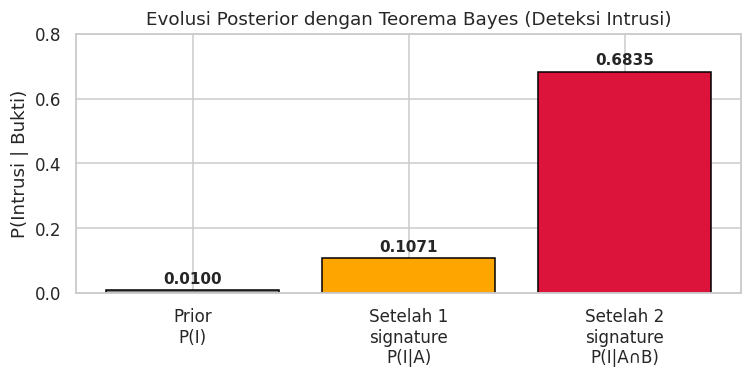

In [ ]:
# ============================================================
# BAB 2 — STUDI KASUS 2.2
# Deteksi Intrusi Jaringan dengan Teorema Bayes
# ============================================================
print("─" * 60)
print("STUDI KASUS 2.2 — Deteksi Intrusi (Teorema Bayes)")
print("─" * 60)

def bayes_update(prior, p_ev_h, p_ev_nh):
    """Bayes satu tahap: kembalikan posterior P(H|E)."""
    p_ev = p_ev_h * prior + p_ev_nh * (1 - prior)
    return p_ev_h * prior / p_ev

p_I = 0.01
p1  = bayes_update(p_I, 0.95, 0.08)        # P(I | A)
p2  = bayes_update(p1,  0.90, 0.05)        # P(I | A ∩ B)

print(f"P(I|A)   Python : {p1:.6f}   (eksak 95/887 = {95/887:.6f})")
print(f"P(I|A∩B) Python : {p2:.6f}   (eksak 95/139 = {95/139:.6f})")

# --- Verifikasi Monte Carlo ---
rng = np.random.default_rng(7)
m   = 1_000_000
I = rng.random(m) < 0.01
A = rng.random(m) < np.where(I, 0.95, 0.08)
B = rng.random(m) < np.where(I, 0.90, 0.05)
print(f"MC P(I|A)       : {I[A].mean():.6f}")
print(f"MC P(I|A∩B)     : {I[A & B].mean():.6f}")

# --- Visualisasi evolusi posterior ---
labels = ["Prior\nP(I)", "Setelah 1\nsignature\nP(I|A)", "Setelah 2\nsignature\nP(I|A∩B)"]
values = [p_I, p1, p2]
fig, ax = plt.subplots(figsize=(7, 3.6))
bars = ax.bar(labels, values, color=["gray", "orange", "crimson"], edgecolor="black")
for b, v in zip(bars, values):
    ax.text(b.get_x() + b.get_width()/2, v + 0.02, f"{v:.4f}",
            ha="center", fontsize=10, fontweight="bold")
ax.set_ylim(0, 0.8)
ax.set(title="Evolusi Posterior dengan Teorema Bayes (Deteksi Intrusi)",
       ylabel="P(Intrusi | Bukti)")
plt.tight_layout(); plt.show()

────────────────────────────────────────────────────────────
STUDI KASUS 2.3 — Simulasi Monte Carlo Uptime Jaringan
────────────────────────────────────────────────────────────
R_sys eksak : 0.998875125
R_sys MC    : 0.998855 ± 0.000066 (95% CI)
Selisih     : 2.01e-05  (SE = 3.38e-05)
Downtime    : 591.2 menit/tahun ≈ 9.85 jam


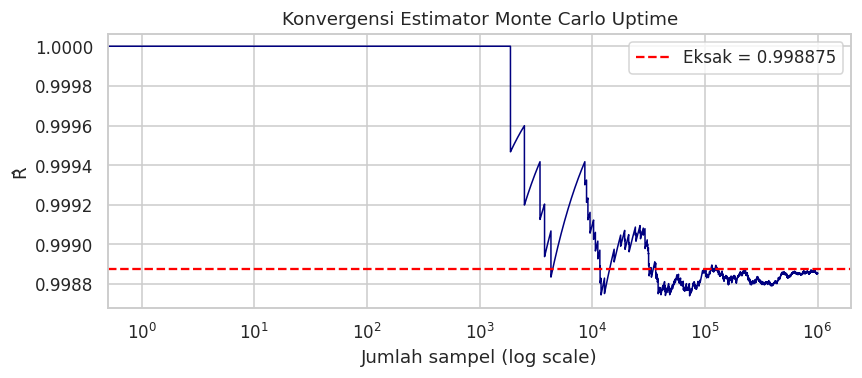

In [ ]:
# ============================================================
# BAB 2 — STUDI KASUS 2.3
# Simulasi Monte Carlo untuk Uptime Jaringan
# ============================================================
print("─" * 60)
print("STUDI KASUS 2.3 — Simulasi Monte Carlo Uptime Jaringan")
print("─" * 60)

p_lb, p_s, N_mc = 0.999, 0.95, 1_000_000
rng = np.random.default_rng(2024)

lb_up  = rng.random(N_mc) < p_lb
srv_up = rng.random((N_mc, 3)) < p_s
sys_up = lb_up & srv_up.any(axis=1)

p_hat   = sys_up.mean()
se_mc   = np.sqrt(p_hat * (1 - p_hat) / N_mc)
p_exact = p_lb * (1 - (1 - p_s) ** 3)

print(f"R_sys eksak : {p_exact:.9f}")
print(f"R_sys MC    : {p_hat:.6f} ± {1.96*se_mc:.6f} (95% CI)")
print(f"Selisih     : {abs(p_hat - p_exact):.2e}  (SE = {se_mc:.2e})")
dt_menit    = 525_600 * (1 - p_exact)
print(f"Downtime    : {dt_menit:.1f} menit/tahun ≈ {dt_menit/60:.2f} jam")

# --- Konvergensi estimator ---
cum_mean = np.cumsum(sys_up) / np.arange(1, N_mc + 1)
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(cum_mean, color="navy", lw=1)
ax.axhline(p_exact, color="red", ls="--", label=f"Eksak = {p_exact:.6f}")
ax.set_xscale("log")
ax.set(title="Konvergensi Estimator Monte Carlo Uptime",
       xlabel="Jumlah sampel (log scale)", ylabel="R̂")
ax.legend()
plt.tight_layout(); plt.show()

────────────────────────────────────────────────────────────
DISTRIBUSI BINOMIAL — Packet Loss (n=20, p=0.05)
────────────────────────────────────────────────────────────
E[X]     = 1.0000   (manual: 1.0000)
Var(X)   = 0.9500   (manual: 0.9500)
P(X=0)   = 0.358486
P(X=2)   = 0.188677
P(X<=2)  = 0.924516
P(X>=3)  = 0.075484
P(X>=1)  = 0.641514


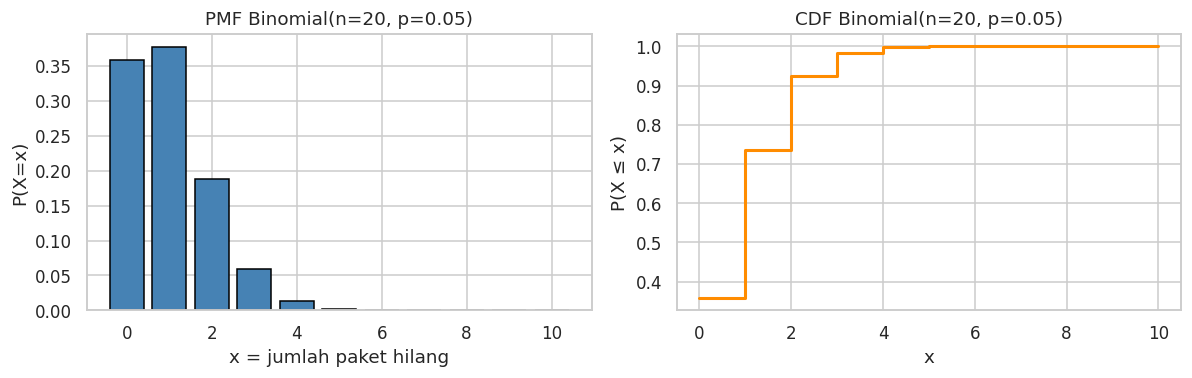

In [ ]:
# ============================================================
# BAB 3 — DISTRIBUSI BINOMIAL
# Kasus: Packet Loss pada Transmisi Data
# ============================================================
print("─" * 60)
print("DISTRIBUSI BINOMIAL — Packet Loss (n=20, p=0.05)")
print("─" * 60)

n_b, p_b = 20, 0.05
rv_b = binom(n_b, p_b)

print(f"E[X]     = {rv_b.mean():.4f}   (manual: {n_b*p_b:.4f})")
print(f"Var(X)   = {rv_b.var():.4f}   (manual: {n_b*p_b*(1-p_b):.4f})")
print(f"P(X=0)   = {rv_b.pmf(0):.6f}")
print(f"P(X=2)   = {rv_b.pmf(2):.6f}")
print(f"P(X<=2)  = {rv_b.cdf(2):.6f}")
print(f"P(X>=3)  = {rv_b.sf(2):.6f}")
print(f"P(X>=1)  = {rv_b.sf(0):.6f}")

# --- PMF & CDF plot ---
x_b = np.arange(0, 11)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].bar(x_b, rv_b.pmf(x_b), color="steelblue", edgecolor="black")
ax[0].set(title="PMF Binomial(n=20, p=0.05)",
          xlabel="x = jumlah paket hilang", ylabel="P(X=x)")
ax[1].step(x_b, rv_b.cdf(x_b), where="post", color="darkorange", lw=2)
ax[1].set(title="CDF Binomial(n=20, p=0.05)",
          xlabel="x", ylabel="P(X ≤ x)")
plt.tight_layout(); plt.show()

────────────────────────────────────────────────────────────
DISTRIBUSI POISSON — Laju Request API (λ=8)
────────────────────────────────────────────────────────────
E[X]     = 8.0000   (manual: 8)
Var(X)   = 8.0000   (manual: 8)
P(X=5)   = 0.091604
P(X<=5)  = 0.191236
P(X>=10) = 0.283376


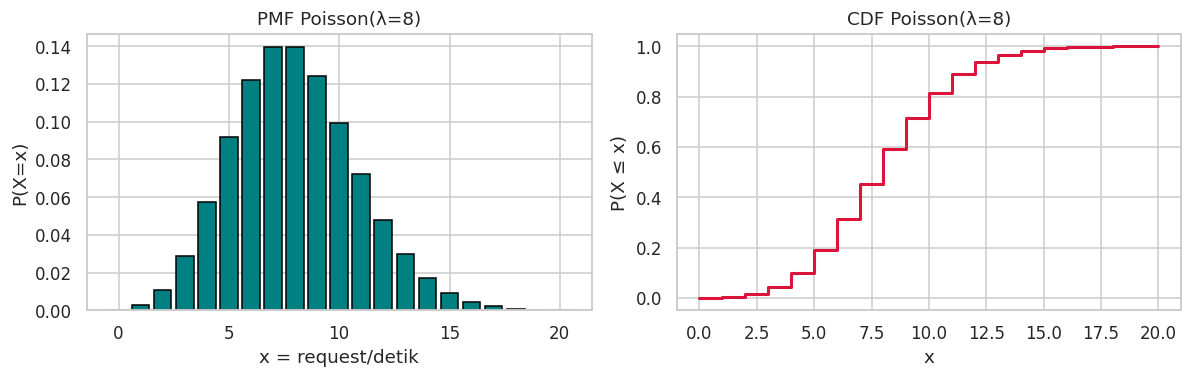

In [ ]:
# ============================================================
# BAB 3 — DISTRIBUSI POISSON
# Kasus: Laju Kedatangan Request ke Server
# ============================================================
print("─" * 60)
print("DISTRIBUSI POISSON — Laju Request API (λ=8)")
print("─" * 60)

lam_p = 8
rv_p = poisson(lam_p)
print(f"E[X]     = {rv_p.mean():.4f}   (manual: {lam_p})")
print(f"Var(X)   = {rv_p.var():.4f}   (manual: {lam_p})")
print(f"P(X=5)   = {rv_p.pmf(5):.6f}")
print(f"P(X<=5)  = {rv_p.cdf(5):.6f}")
print(f"P(X>=10) = {rv_p.sf(9):.6f}")

# --- PMF & CDF plot ---
x_p = np.arange(0, 21)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].bar(x_p, rv_p.pmf(x_p), color="teal", edgecolor="black")
ax[0].set(title="PMF Poisson(λ=8)",
          xlabel="x = request/detik", ylabel="P(X=x)")
ax[1].step(x_p, rv_p.cdf(x_p), where="post", color="crimson", lw=2)
ax[1].set(title="CDF Poisson(λ=8)", xlabel="x", ylabel="P(X ≤ x)")
plt.tight_layout(); plt.show()

────────────────────────────────────────────────────────────
DISTRIBUSI NORMAL — Latensi API (μ=200, σ=30)
────────────────────────────────────────────────────────────
E[X]         = 200.00   Var = 900.00   σ = 30.00
P(X>250)     = 0.047790
P(180<X<220) = 0.495015
P(X<150)     = 0.047790


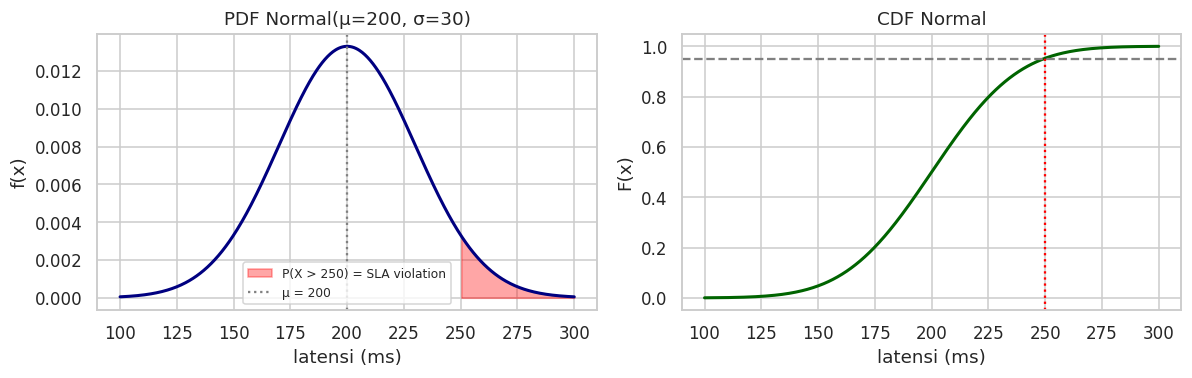

In [ ]:
# ============================================================
# BAB 3 — DISTRIBUSI NORMAL
# Kasus: Latensi Respons API (μ=200, σ=30)
# ============================================================
print("─" * 60)
print("DISTRIBUSI NORMAL — Latensi API (μ=200, σ=30)")
print("─" * 60)

mu_n, sg_n = 200, 30
rv_n = norm(mu_n, sg_n)
print(f"E[X]         = {rv_n.mean():.2f}   Var = {rv_n.var():.2f}   σ = {rv_n.std():.2f}")
print(f"P(X>250)     = {rv_n.sf(250):.6f}")
print(f"P(180<X<220) = {rv_n.cdf(220) - rv_n.cdf(180):.6f}")
print(f"P(X<150)     = {rv_n.cdf(150):.6f}")

# --- PDF (dengan shading SLA) & CDF plot ---
x_n = np.linspace(100, 300, 500)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(x_n, rv_n.pdf(x_n), color="navy", lw=2)
ax[0].fill_between(x_n, rv_n.pdf(x_n), where=(x_n > 250),
                   alpha=0.35, color="red", label="P(X > 250) = SLA violation")
ax[0].axvline(mu_n, color="gray", ls=":", label=f"μ = {mu_n}")
ax[0].set(title="PDF Normal(μ=200, σ=30)",
          xlabel="latensi (ms)", ylabel="f(x)")
ax[0].legend(fontsize=8)
ax[1].plot(x_n, rv_n.cdf(x_n), color="darkgreen", lw=2)
ax[1].axhline(0.95, ls="--", color="gray")
ax[1].axvline(250, ls=":", color="red")
ax[1].set(title="CDF Normal", xlabel="latensi (ms)", ylabel="F(x)")
plt.tight_layout(); plt.show()

────────────────────────────────────────────────────────────
DISTRIBUSI EKSPONENSIAL — Antar-Kedatangan (λ=0.5)
────────────────────────────────────────────────────────────
E[X]     = 2.0000   Var = 4.0000   σ = 2.0000
P(X<1)   = 0.393469
P(X>3)   = 0.223130
P(1<X<3) = 0.383400
Median   = 1.3863
P(X>5|X>2) = 0.223130   vs   P(X>3) = 0.223130


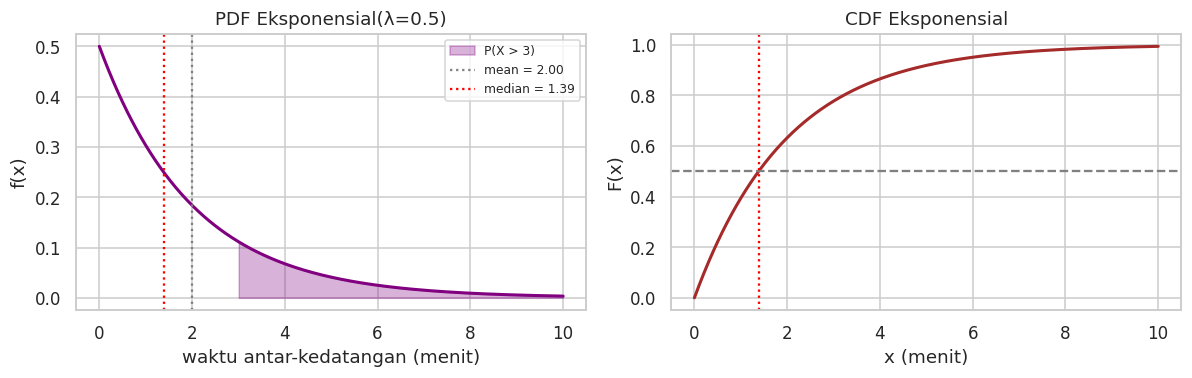

In [ ]:
# ============================================================
# BAB 3 — DISTRIBUSI EKSPONENSIAL
# Kasus: Waktu Antar-Kedatangan Request (λ=0.5/menit)
# ============================================================
print("─" * 60)
print("DISTRIBUSI EKSPONENSIAL — Antar-Kedatangan (λ=0.5)")
print("─" * 60)

lam_e = 0.5
rv_e = expon(scale=1 / lam_e)              # SciPy: scale = 1/λ
print(f"E[X]     = {rv_e.mean():.4f}   Var = {rv_e.var():.4f}   σ = {rv_e.std():.4f}")
print(f"P(X<1)   = {rv_e.cdf(1):.6f}")
print(f"P(X>3)   = {rv_e.sf(3):.6f}")
print(f"P(1<X<3) = {rv_e.cdf(3) - rv_e.cdf(1):.6f}")
print(f"Median   = {rv_e.median():.4f}")
print(f"P(X>5|X>2) = {rv_e.sf(5)/rv_e.sf(2):.6f}   vs   P(X>3) = {rv_e.sf(3):.6f}")

# --- PDF (shading P(X>3)) & CDF plot ---
x_e = np.linspace(0, 10, 500)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(x_e, rv_e.pdf(x_e), color="purple", lw=2)
ax[0].fill_between(x_e, rv_e.pdf(x_e), where=(x_e > 3),
                   alpha=0.3, color="purple", label="P(X > 3)")
ax[0].axvline(rv_e.mean(), color="gray", ls=":", label=f"mean = {rv_e.mean():.2f}")
ax[0].axvline(rv_e.median(), color="red", ls=":", label=f"median = {rv_e.median():.2f}")
ax[0].set(title="PDF Eksponensial(λ=0.5)",
          xlabel="waktu antar-kedatangan (menit)", ylabel="f(x)")
ax[0].legend(fontsize=8)
ax[1].plot(x_e, rv_e.cdf(x_e), color="brown", lw=2)
ax[1].axhline(0.5, ls="--", color="gray")
ax[1].axvline(rv_e.median(), ls=":", color="red")
ax[1].set(title="CDF Eksponensial", xlabel="x (menit)", ylabel="F(x)")
plt.tight_layout(); plt.show()

REKAPITULASI — Parameter & Statistik Ringkas
            Distribusi       E[X]     Var(X)                    Kasus
Binomial(n=20, p=0.05)   1.000000   0.950000              Packet loss
          Poisson(λ=8)   8.000000   8.000000            Request/detik
   Normal(μ=200, σ=30) 200.000000 900.000000         Latensi API (ms)
   Eksponensial(λ=0.5)   2.000000   4.000000 Antar-kedatangan (menit)


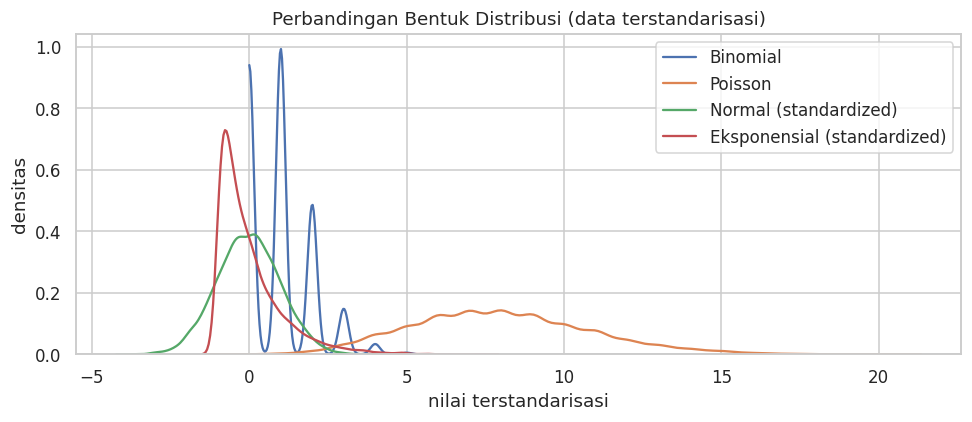


✅ Laporan selesai — semua sel konsisten dengan Bab 2 & Bab 3.


In [ ]:
# ============================================================
# REKAPITULASI AKHIR — Tabel & Perbandingan Bentuk Distribusi
# Jalankan setelah Cell 4–7
# ============================================================
print("=" * 60)
print("REKAPITULASI — Parameter & Statistik Ringkas")
print("=" * 60)

rekap = pd.DataFrame([
    {"Distribusi": "Binomial(n=20, p=0.05)", "E[X]": 1.0,   "Var(X)": 0.95,  "Kasus": "Packet loss"},
    {"Distribusi": "Poisson(λ=8)",           "E[X]": 8.0,   "Var(X)": 8.0,   "Kasus": "Request/detik"},
    {"Distribusi": "Normal(μ=200, σ=30)",    "E[X]": 200.0, "Var(X)": 900.0, "Kasus": "Latensi API (ms)"},
    {"Distribusi": "Eksponensial(λ=0.5)",    "E[X]": 2.0,   "Var(X)": 4.0,   "Kasus": "Antar-kedatangan (menit)"},
])
print(rekap.to_string(index=False))

# --- Perbandingan bentuk (KDE overlay) ---
samp_b = binom(20, 0.05).rvs(size=10_000, random_state=1)
samp_p = poisson(8).rvs(size=10_000, random_state=2)
samp_n = norm(200, 30).rvs(size=10_000, random_state=3)
samp_e = expon(scale=2).rvs(size=10_000, random_state=4)

fig, ax = plt.subplots(figsize=(9, 4))
sns.kdeplot(samp_b, ax=ax, label="Binomial", clip=(0, None))
sns.kdeplot(samp_p, ax=ax, label="Poisson")
sns.kdeplot((samp_n - 200) / 30, ax=ax, label="Normal (standardized)")
sns.kdeplot((samp_e - 2) / 2, ax=ax, label="Eksponensial (standardized)")
ax.set(title="Perbandingan Bentuk Distribusi (data terstandarisasi)",
       xlabel="nilai terstandarisasi", ylabel="densitas")
ax.legend(); plt.tight_layout(); plt.show()

print("\n✅ Laporan selesai — semua sel konsisten dengan Bab 2 & Bab 3.")